# Machine learning on the scraped data: predicting Premier League 2023-2024 matches
**Team:** Jana Alamir, Rim Zoghbi
**Data:** 380 matches scraped from TheSportsDB (`data/matches_api.csv`; identical to the BS4 and Selenium datasets)
**Goal:** predict the scores (regression) and the results W/D/L (classification) of the last 100 matches,
using only information available before each match.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/matches_api.csv", parse_dates=["date"])

print("Shape:", df.shape)
display(df.head())
print(df.dtypes, "\n")

print("Missing values:", df.isnull().sum().sum())
print("Teams:", pd.concat([df["home_team"], df["away_team"]]).nunique())
print("Date range:", df["date"].min().date(), "->", df["date"].max().date())

print("\nResults (from the home team's view):")
results = pd.DataFrame({
    "count": df["result"].value_counts(),
    "percent": (df["result"].value_counts(normalize=True) * 100).round(1),
})
display(results)

print("Goals per match:")
display(df[["home_goals", "away_goals"]].describe().round(2))

Shape: (380, 7)


,date,round,home_team,away_team,home_goals,away_goals,result
0,2023-08-11,1,Burnley,Manchester City,0,3,L
1,2023-08-12,1,Arsenal,Nottingham Forest,2,1,W
2,2023-08-12,1,Bournemouth,West Ham,1,1,D
3,2023-08-12,1,Brighton,Luton,4,1,W
4,2023-08-12,1,Everton,Fulham,0,1,L


date          datetime64[us]
round                  int64
home_team                str
away_team                str
home_goals             int64
away_goals             int64
result                   str
dtype: object 

Missing values: 0
Teams: 20
Date range: 2023-08-11 -> 2024-05-19

Results (from the home team's view):


,count,percent
result,,
W,175,46.1
L,123,32.4
D,82,21.6


Goals per match:


,home_goals,away_goals
count,380.00,380.00
mean,1.80,1.48
std,1.37,1.28
min,0.00,0.00
25%,1.00,1.00
50%,2.00,1.00
75%,3.00,2.00
max,6.00,8.00


## 1. Exploratory data analysis

Home advantage: 0.32 goals per match


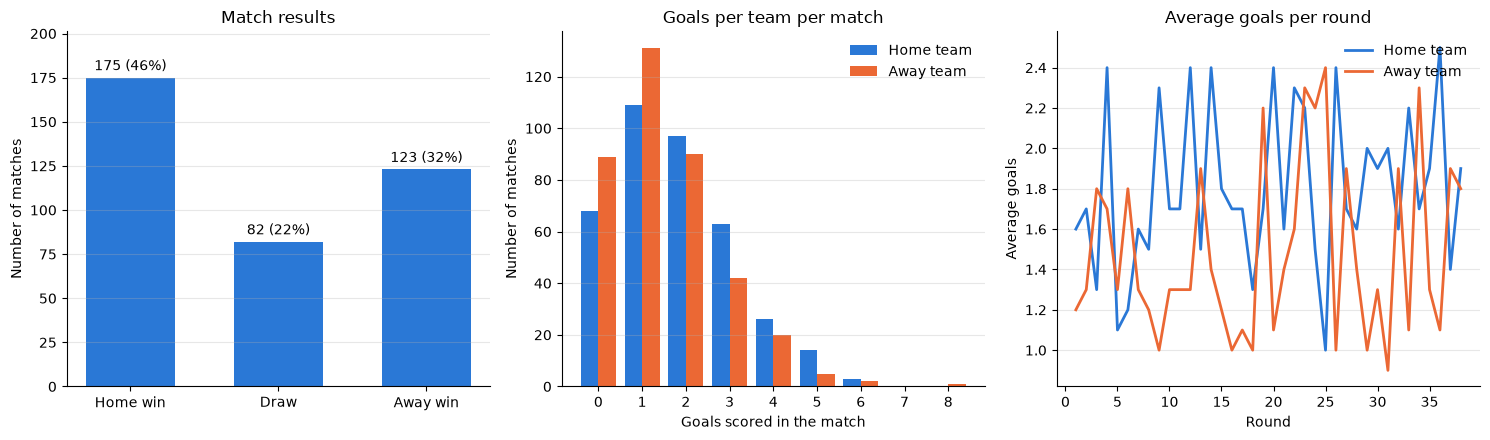

In [2]:
import os
os.makedirs("figures", exist_ok=True)

HOME_COLOR, AWAY_COLOR = "#2a78d6", "#eb6834"
print(f"Home advantage: {df['home_goals'].mean() - df['away_goals'].mean():.2f} goals per match")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# 1. How often does each result happen?
order = ["W", "D", "L"]
names = ["Home win", "Draw", "Away win"]
counts = df["result"].value_counts().loc[order]
bars = axes[0].bar(names, counts, color=HOME_COLOR, width=0.6)
axes[0].bar_label(bars, labels=[f"{c} ({c / len(df):.0%})" for c in counts], padding=3)
axes[0].set_ylim(top=counts.max() * 1.15)
axes[0].set_ylabel("Number of matches")
axes[0].set_title("Match results")

# 2. How many goals does a team score in a match?
goals = list(range(0, 9))
home_counts = df["home_goals"].value_counts().reindex(goals, fill_value=0)
away_counts = df["away_goals"].value_counts().reindex(goals, fill_value=0)
width = 0.4
axes[1].bar([g - width / 2 for g in goals], home_counts, width, label="Home team", color=HOME_COLOR)
axes[1].bar([g + width / 2 for g in goals], away_counts, width, label="Away team", color=AWAY_COLOR)
axes[1].set_xticks(goals)
axes[1].set_xlabel("Goals scored in the match")
axes[1].set_ylabel("Number of matches")
axes[1].set_title("Goals per team per match")
axes[1].legend(frameon=False)

# 3. Does scoring change during the season?
per_round = df.groupby("round")[["home_goals", "away_goals"]].mean()
axes[2].plot(per_round.index, per_round["home_goals"], color=HOME_COLOR, linewidth=2, label="Home team")
axes[2].plot(per_round.index, per_round["away_goals"], color=AWAY_COLOR, linewidth=2, label="Away team")
axes[2].set_xlabel("Round")
axes[2].set_ylabel("Average goals")
axes[2].set_title("Average goals per round")
axes[2].legend(frameon=False)

for ax in axes:
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig("figures/ml_eda.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Features (only information available before each match)
For each team: form (points in its last 5 matches), average goals scored and conceded in its last 5 matches.
`shift(1)` excludes the current match, so a match never uses its own result (no data leakage).

In [3]:
# 1. One row per team per match: each match appears twice (home side and away side)
home_side = pd.DataFrame({
    "match_id": df.index, "date": df["date"], "team": df["home_team"],
    "goals_for": df["home_goals"], "goals_against": df["away_goals"],
})
away_side = pd.DataFrame({
    "match_id": df.index, "date": df["date"], "team": df["away_team"],
    "goals_for": df["away_goals"], "goals_against": df["home_goals"],
})
team_matches = pd.concat([home_side, away_side]).sort_values(["date", "match_id"]).reset_index(drop=True)

# 2. Points won in each match: win = 3, draw = 1, loss = 0
team_matches["points"] = 0
team_matches.loc[team_matches["goals_for"] > team_matches["goals_against"], "points"] = 3
team_matches.loc[team_matches["goals_for"] == team_matches["goals_against"], "points"] = 1

# 3. Average over the team's PREVIOUS 5 matches (shift(1) = the current match is excluded)
def last5_average(column):
    return team_matches.groupby("team")[column].transform(
        lambda values: values.shift(1).rolling(5, min_periods=1).mean()
    )

team_matches["form"] = last5_average("points") * 5        # = points in the last 5 matches
team_matches["avg_scored"] = last5_average("goals_for")
team_matches["avg_conceded"] = last5_average("goals_against")

# 4. Put the features back into the match table: once for the home team, once for the away team
features = team_matches[["match_id", "team", "form", "avg_scored", "avg_conceded"]]
data = df.copy()
data["match_id"] = data.index
data = data.merge(
    features.rename(columns={"team": "home_team", "form": "home_form",
                             "avg_scored": "home_avg_scored", "avg_conceded": "home_avg_conceded"}),
    on=["match_id", "home_team"])
data = data.merge(
    features.rename(columns={"team": "away_team", "form": "away_form",
                             "avg_scored": "away_avg_scored", "avg_conceded": "away_avg_conceded"}),
    on=["match_id", "away_team"])
data = data.sort_values("match_id").reset_index(drop=True)

FEATURES = ["home_form", "home_avg_scored", "home_avg_conceded",
            "away_form", "away_avg_scored", "away_avg_conceded"]

print("Matches without history (a team's first match):", data[FEATURES].isnull().any(axis=1).sum())
display(data[["date", "home_team", "away_team", "home_goals", "away_goals"] + FEATURES].iloc[18:24].round(2))

# Hand check: Arsenal's first 7 matches
print("Check - Arsenal's first matches:")
arsenal = team_matches[team_matches["team"] == "Arsenal"].head(7)
display(arsenal[["date", "goals_for", "goals_against", "points", "form", "avg_scored", "avg_conceded"]].round(2))

Matches without history (a team's first match): 10


/tmp/ipykernel_33947/1661755093.py:45: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(data[["date", "home_team", "away_team", "home_goals", "away_goals"] + FEATURES].iloc[18:24].round(2))


,date,home_team,away_team,home_goals,away_goals,home_form,home_avg_scored,home_avg_conceded,away_form,away_avg_scored,away_avg_conceded
18,2023-08-21,Crystal Palace,Arsenal,0,1,15.0,1.0,0.0,15.0,2.0,1.0
19,2023-08-25,Chelsea,Luton,3,0,2.5,1.0,2.0,0.0,1.0,4.0
20,2023-08-26,Arsenal,Fulham,2,2,15.0,1.5,0.5,7.5,0.5,1.5
21,2023-08-26,Bournemouth,Tottenham,0,2,2.5,1.0,2.0,10.0,2.0,1.0
22,2023-08-26,Brentford,Crystal Palace,1,1,10.0,2.5,1.0,7.5,0.5,0.5
23,2023-08-26,Brighton,West Ham,1,3,15.0,4.0,1.0,10.0,2.0,1.0


Check - Arsenal's first matches:


/tmp/ipykernel_33947/1661755093.py:50: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(arsenal[["date", "goals_for", "goals_against", "points", "form", "avg_scored", "avg_conceded"]].round(2))


,date,goals_for,goals_against,points,form,avg_scored,avg_conceded
2,2023-08-12,2,1,3,NaN,NaN,NaN
37,2023-08-21,1,0,3,15.00,2.00,1.0
40,2023-08-26,2,2,1,15.00,1.50,0.5
72,2023-09-03,3,1,3,11.67,1.67,1.0
95,2023-09-17,1,0,3,12.50,2.00,1.0
108,2023-09-24,2,2,1,13.00,1.80,0.8
121,2023-09-30,4,0,3,11.00,1.80,1.0


## 3. Train/test split (by time) and baseline
Train: the first 280 matches (minus the 10 round-1 matches with no history). Test: the last 100 matches.
No shuffling: the model learns from the past and is evaluated on the future.

In [4]:
train = data.iloc[:280].dropna(subset=FEATURES)
test = data.iloc[280:]

print(f"Train: {len(train)} matches, {train['date'].min().date()} -> {train['date'].max().date()}")
print(f"Test : {len(test)} matches, {test['date'].min().date()} -> {test['date'].max().date()}")
print("Missing features in test:", test[FEATURES].isnull().sum().sum())

distribution = pd.DataFrame({
    "train %": (train["result"].value_counts(normalize=True) * 100).round(1),
    "test %": (test["result"].value_counts(normalize=True) * 100).round(1),
}).loc[["W", "D", "L"]]
display(distribution)

X_train, X_test = train[FEATURES], test[FEATURES]

# Baseline: always predict a home win
baseline_accuracy = (test["result"] == "W").mean()
print(f"Baseline 'always home win' accuracy on the test set: {baseline_accuracy:.1%}")

Train: 270 matches, 2023-08-18 -> 2024-03-16
Test : 100 matches, 2024-03-16 -> 2024-05-19
Missing features in test: 0


,train %,test %
result,,
W,46.3,46.0
D,20.0,25.0
L,33.7,29.0


Baseline 'always home win' accuracy on the test set: 46.0%


## 4. Regression: predicting the number of goals
Two targets (home goals, away goals), two models each. Metric: MAE (mean absolute error, in goals).
Baseline: always predict the average number of goals of the training matches.

In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

regression_results = []
predicted_goals = {}

for target in ["home_goals", "away_goals"]:
    y_train, y_test = train[target], test[target]

    # Baseline: always predict the training average
    baseline_mae = mean_absolute_error(y_test, [y_train.mean()] * len(y_test))
    regression_results.append({"model": "Baseline (train average)", "target": target, "MAE": baseline_mae})

    models = {
        "Linear Regression": LinearRegression(),
        "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42),
    }
    for name, model in models.items():
        model.fit(X_train, y_train)                 # learn from the first 270 matches
        predictions = model.predict(X_test)         # predict the last 100
        predicted_goals[(target, name)] = predictions
        regression_results.append({"model": name, "target": target,
                                   "MAE": mean_absolute_error(y_test, predictions)})

mae_table = (pd.DataFrame(regression_results)
             .pivot(index="model", columns="target", values="MAE")
             .loc[["Baseline (train average)", "Linear Regression", "Random Forest"]]
             .round(3))
display(mae_table)

# What did the linear model learn? (one weight per feature, for home goals)
linear_home = LinearRegression().fit(X_train, train["home_goals"])
print("Linear Regression weights for home goals:")
print(pd.Series(linear_home.coef_, index=FEATURES).round(3))

target,away_goals,home_goals
model,,
Baseline (train average),1.040,1.158
Linear Regression,0.933,1.080
Random Forest,0.986,1.128


Linear Regression weights for home goals:
home_form            0.005
home_avg_scored      0.252
home_avg_conceded   -0.098
away_form           -0.042
away_avg_scored     -0.050
away_avg_conceded    0.089
dtype: float64


## 5. Classification: predicting the result (W/D/L, home team's view)
Two models. Metrics: accuracy and confusion matrix, compared with the "always home win" baseline (46.0% on the test set).

,accuracy %,predicted W / D / L
model,,
Baseline (always home win),46.0,100 / 0 / 0
Logistic Regression,58.0,64 / 0 / 36
Random Forest,52.0,64 / 1 / 35


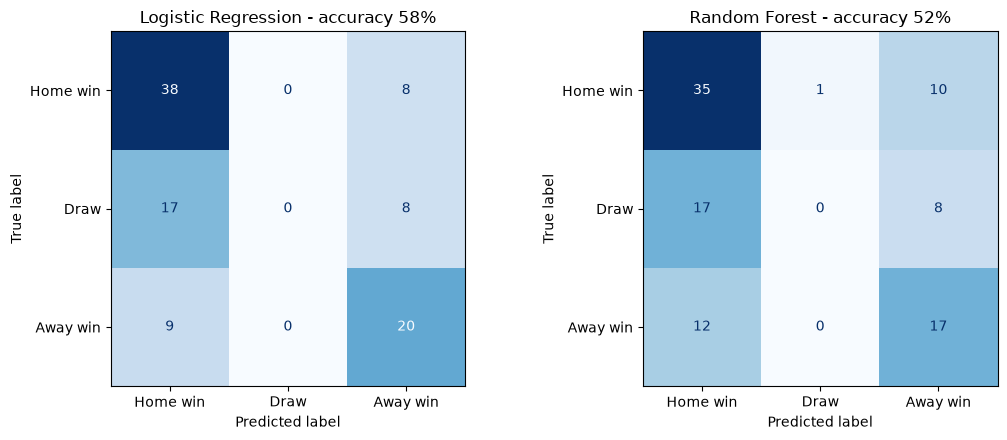

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

LABELS = ["W", "D", "L"]
y_train_result, y_test_result = train["result"], test["result"]

classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=42),
}

rows = [{"model": "Baseline (always home win)", "accuracy %": round(baseline_accuracy * 100, 1),
         "predicted W / D / L": "100 / 0 / 0"}]
predicted_results = {}

for name, model in classifiers.items():
    model.fit(X_train, y_train_result)
    predictions = model.predict(X_test)
    predicted_results[name] = predictions
    counts = pd.Series(predictions).value_counts().reindex(LABELS, fill_value=0)
    rows.append({"model": name,
                 "accuracy %": round(accuracy_score(y_test_result, predictions) * 100, 1),
                 "predicted W / D / L": " / ".join(str(c) for c in counts)})

accuracy_table = pd.DataFrame(rows).set_index("model")
display(accuracy_table)

# Confusion matrices: rows = real result, columns = predicted result
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, predictions) in zip(axes, predicted_results.items()):
    matrix = confusion_matrix(y_test_result, predictions, labels=LABELS)
    ConfusionMatrixDisplay(matrix, display_labels=["Home win", "Draw", "Away win"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name} - accuracy {accuracy_score(y_test_result, predictions):.0%}")
fig.tight_layout()
fig.savefig("figures/ml_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Predictions for the last 100 matches
Scores: Linear Regression (best MAE). Results: Logistic Regression (best accuracy).
The full table is saved as `data/predictions_last100.csv`.

In [7]:
best_home = predicted_goals[("home_goals", "Linear Regression")]
best_away = predicted_goals[("away_goals", "Linear Regression")]

prediction_table = pd.DataFrame({
    "date": test["date"].dt.date,
    "home_team": test["home_team"],
    "away_team": test["away_team"],
    "real_score": test["home_goals"].astype(str) + "-" + test["away_goals"].astype(str),
    "predicted_goals": [f"{h:.1f}-{a:.1f}" for h, a in zip(best_home, best_away)],
    "predicted_score": [f"{round(h)}-{round(a)}" for h, a in zip(best_home, best_away)],
    "real_result": test["result"],
    "predicted_result": predicted_results["Logistic Regression"],
}).reset_index(drop=True)

prediction_table["correct_result"] = prediction_table["real_result"] == prediction_table["predicted_result"]
prediction_table["exact_score"] = prediction_table["real_score"] == prediction_table["predicted_score"]

print("Correct results:", prediction_table["correct_result"].sum(), "/ 100")
print("Exact scores   :", prediction_table["exact_score"].sum(), "/ 100")

prediction_table.to_csv("data/predictions_last100.csv", index=False)
display(prediction_table.head(20))

Correct results: 58 / 100
Exact scores   : 9 / 100


,date,home_team,away_team,real_score,predicted_goals,predicted_score,real_result,predicted_result,correct_result,exact_score
0,2024-03-16,Fulham,Tottenham,3-0,1.7-1.7,2-2,W,W,True,False
1,2024-03-16,Luton,Nottingham Forest,1-1,1.8-1.7,2-2,D,W,False,False
2,2024-03-17,West Ham,Aston Villa,1-1,1.7-1.2,2-1,D,W,False,False
3,2024-03-30,Aston Villa,Wolves,2-0,1.8-0.9,2-1,W,W,True,False
4,2024-03-30,Bournemouth,Everton,2-1,2.2-1.1,2-1,W,W,True,True
5,2024-03-30,Brentford,Manchester United,1-1,1.5-1.8,1-2,D,L,False,False
6,2024-03-30,Chelsea,Burnley,2-2,2.2-0.8,2-1,D,W,False,False
7,2024-03-30,Newcastle,West Ham,4-3,1.8-1.5,2-1,W,W,True,False
8,2024-03-30,Nottingham Forest,Crystal Palace,1-1,1.7-1.8,2-2,D,W,False,False
9,2024-03-30,Sheffield United,Fulham,3-3,1.3-1.9,1-2,D,L,False,False


## 7. Conclusion

**Setup.** 380 matches scraped from TheSportsDB (all three scraping methods produced identical data).
Features use only matches played before each match: form (points in the last 5 matches), average goals scored
and conceded in the last 5, for the home and the away team. Train: first 280 matches (270 with history). Test: last 100.

**Regression (goals), MAE on the last 100 matches:**

| Model | Home goals | Away goals |
|---|---|---|
| Baseline (train average) | 1.158 | 1.040 |
| Linear Regression | **1.080** | **0.933** |
| Random Forest | 1.128 | 0.986 |

**Classification (W/D/L), accuracy on the last 100 matches:**

| Model | Accuracy |
|---|---|
| Baseline (always home win) | 46% |
| Logistic Regression | **58%** |
| Random Forest | 52% |

**Findings**
- Both model types beat their baselines: the scraped data contains real predictive information.
- The simpler linear models beat Random Forest in both tasks: with only 270 training matches, Random Forest overfits.
- The models never predict draws. Draws are the rarest result (20% of training matches) and look like narrow wins
  in our features, so all 25 draws in the test set were missed.
- 58 / 100 results and 9 / 100 exact scores were predicted correctly.

**Limits**
- One season only: 270 training matches and 100 test matches. Each test match is worth 1 percentage point,
  so the uncertainty on the accuracy is about ±5 points, and the difference between the two models (6 matches) could be chance.
- Simple features: no shots, expected goals, injuries, head-to-head history or rest days.
- Predicted scores are rounded averages, which is not the most likely score (1.7-1.7 becomes 2-2 instead of 1-1).

**Possible improvements**
- Scrape several seasons with the same scrapers (more training data).
- Add richer features (shots, expected goals, days of rest between matches).
- Predict scores with a Poisson model, which gives the probability of each exact score.
- Use class weights so the classifier is encouraged to predict draws.